<a href="https://colab.research.google.com/github/swetha682/imagined-speech-eeg/blob/main/notebpok_name_Imagined_Speech_CWT_Scalogram_Generation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

Mounted at /content/gdrive


In [2]:
!pip install PyWavelets scipy numpy pandas matplotlib seaborn -q

In [3]:
import os
import re
import glob
import numpy as np
import pandas as pd
import scipy.io as sio
import pywt
import matplotlib.pyplot as plt

from scipy.signal import butter, sosfiltfilt
from pathlib import Path
from tqdm.notebook import tqdm

print("All libraries imported successfully.")
print("PyWavelets version:", pywt.__version__)

All libraries imported successfully.
PyWavelets version: 1.8.0


In [4]:
MYDRIVE = "/content/gdrive/MyDrive"

PROJECT_DIR = os.path.join(
    MYDRIVE, "Imagined_Speech_EEG_Project"
)

DATASET_DIR = os.path.join(
    PROJECT_DIR, "dataset"
)

VALIDATION_DIR = os.path.join(
    DATASET_DIR, "Validation set"
)

OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "experiment_outputs",
    "CWT_Scalograms"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Dataset directory:", VALIDATION_DIR)
print("Output directory:", OUTPUT_DIR)

print("\nValidation directory exists:",
      os.path.exists(VALIDATION_DIR))

Dataset directory: /content/gdrive/MyDrive/Imagined_Speech_EEG_Project/dataset/Validation set
Output directory: /content/gdrive/MyDrive/Imagined_Speech_EEG_Project/experiment_outputs/CWT_Scalograms

Validation directory exists: True


In [5]:
validation_files = sorted(
    glob.glob(os.path.join(VALIDATION_DIR, "*.mat"))
)

print("Number of validation files:", len(validation_files))

for file in validation_files[:10]:
    print(os.path.basename(file))

Number of validation files: 15
Data_Sample01.mat
Data_Sample02.mat
Data_Sample03.mat
Data_Sample04.mat
Data_Sample05.mat
Data_Sample06.mat
Data_Sample07.mat
Data_Sample08.mat
Data_Sample09.mat
Data_Sample10.mat


In [6]:
sample_file = os.path.join(
    VALIDATION_DIR, "Data_Sample01.mat"
)

mat_data = sio.loadmat(
    sample_file,
    squeeze_me=False
)

epo = mat_data["epo_validation"][0, 0]

X = np.asarray(epo["x"], dtype=np.float64)
y = np.asarray(epo["y"])

fs = float(np.asarray(epo["fs"]).squeeze())

channel_names = [
    str(np.asarray(ch).squeeze().item())
    for ch in np.asarray(epo["clab"]).squeeze()
]

time_values = np.asarray(epo["t"]).squeeze()

print("EEG data shape:", X.shape)
print("Label matrix shape:", y.shape)
print("Sampling frequency:", fs, "Hz")
print("Number of electrodes:", len(channel_names))
print("Number of trials:", X.shape[2])
print("First 15 electrodes:", channel_names[:15])
print("Time vector shape:", time_values.shape)

EEG data shape: (795, 64, 50)
Label matrix shape: (5, 50)
Sampling frequency: 256.0 Hz
Number of electrodes: 64
Number of trials: 50
First 15 electrodes: ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'FC5', 'FC1', 'FC2', 'FC6', 'T7', 'C3', 'Cz', 'C4']
Time vector shape: (795,)


In [8]:
ELECTRODE_NAME = "Cz"

if ELECTRODE_NAME not in channel_names:
    raise ValueError(
        f"{ELECTRODE_NAME} not found in channel names."
    )

electrode_index = channel_names.index(ELECTRODE_NAME)

# Convert EEG to trials x samples
eeg_cz = X[:, electrode_index, :].T

# Convert one-hot labels to class IDs
if y.shape[0] == 5:
    class_ids = np.argmax(y, axis=0)
elif y.shape[1] == 5:
    class_ids = np.argmax(y, axis=1)
else:
    raise ValueError("Unexpected label matrix dimensions.")

class_names = [
    "Hello",
    "Helpme",
    "Stop",
    "Thankyou",
    "Yes"
]

trial_labels = [
    class_names[int(class_id)]
    for class_id in class_ids
]

print("Selected electrode:", ELECTRODE_NAME)
print("Electrode index:", electrode_index)
print("EEG shape:", eeg_cz.shape)

print("\nClass distribution:")
print(pd.Series(trial_labels).value_counts().sort_index())

Selected electrode: Cz
Electrode index: 13
EEG shape: (50, 795)

Class distribution:
Hello       10
Helpme      10
Stop        10
Thankyou    10
Yes         10
Name: count, dtype: int64


In [9]:
FILTER_CONFIGS = {
    "0.5-40Hz": (0.5, 40),
    "1-40Hz": (1, 40)
}

FILTER_ORDER = 4

filtered_signals = {}

for filter_name, (low_cutoff, high_cutoff) in FILTER_CONFIGS.items():

    sos = butter(
        FILTER_ORDER,
        [low_cutoff, high_cutoff],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    filtered_data = sosfiltfilt(
        sos,
        eeg_cz,
        axis=1
    )

    filtered_signals[filter_name] = filtered_data

    print(
        filter_name,
        "output shape:",
        filtered_data.shape
    )

0.5-40Hz output shape: (50, 795)
1-40Hz output shape: (50, 795)


In [10]:
WAVELET = "cmor1.5-1.0"

FREQUENCIES = np.geomspace(
    0.5,
    40,
    96
)

# Convert frequencies into CWT scales
central_frequency = pywt.central_frequency(WAVELET)

SCALES = (
    central_frequency * fs / FREQUENCIES
)

print("Wavelet:", WAVELET)
print("Number of frequency points:", len(FREQUENCIES))
print("Minimum frequency:", FREQUENCIES.min())
print("Maximum frequency:", FREQUENCIES.max())
print("Number of scales:", len(SCALES))

Wavelet: cmor1.5-1.0
Number of frequency points: 96
Minimum frequency: 0.5
Maximum frequency: 40.0
Number of scales: 96


In [11]:
cwt_results = {}

for filter_name, filtered_data in filtered_signals.items():

    print("\nProcessing:", filter_name)

    trial_power_list = []

    for trial_index in tqdm(range(filtered_data.shape[0])):

        signal = filtered_data[trial_index]

        coefficients, cwt_frequencies = pywt.cwt(
            signal,
            SCALES,
            WAVELET,
            sampling_period=1/fs,
            method="fft"
        )

        # Wavelet power
        power = np.abs(coefficients) ** 2

        trial_power_list.append(
            power.astype(np.float32)
        )

    cwt_results[filter_name] = np.stack(
        trial_power_list,
        axis=0
    )

    print(
        "CWT result shape:",
        cwt_results[filter_name].shape
    )

print("\nCWT processing completed.")


Processing: 0.5-40Hz


  0%|          | 0/50 [00:00<?, ?it/s]

CWT result shape: (50, 96, 795)

Processing: 1-40Hz


  0%|          | 0/50 [00:00<?, ?it/s]

CWT result shape: (50, 96, 795)

CWT processing completed.


In [12]:
all_log_power = []

for filter_name in FILTER_CONFIGS:

    log_power = np.log10(
        cwt_results[filter_name] + 1e-12
    )

    all_log_power.append(log_power.ravel())

all_log_power = np.concatenate(all_log_power)

COLOR_MIN = np.percentile(all_log_power, 2)
COLOR_MAX = np.percentile(all_log_power, 98)

print("Common colour minimum:", COLOR_MIN)
print("Common colour maximum:", COLOR_MAX)

Common colour minimum: -1.028442
Common colour maximum: 3.030757


In [13]:
# Convert the dataset's time vector from milliseconds to seconds.
if np.max(np.abs(time_values)) > 10:
    time_seconds = time_values / 1000.0
else:
    time_seconds = time_values

for filter_name in FILTER_CONFIGS:

    print("\nGenerating images for:", filter_name)

    filter_output_dir = os.path.join(
        OUTPUT_DIR,
        filter_name,
        ELECTRODE_NAME
    )

    for class_name in class_names:
        os.makedirs(
            os.path.join(filter_output_dir, class_name),
            exist_ok=True
        )

    log_power = np.log10(
        cwt_results[filter_name] + 1e-12
    )

    for trial_index in tqdm(range(len(trial_labels))):

        label = trial_labels[trial_index]

        scalogram = log_power[trial_index]

        plt.figure(figsize=(10, 5))

        plt.pcolormesh(
            time_seconds,
            cwt_frequencies,
            scalogram,
            shading="auto",
            cmap="jet",
            vmin=COLOR_MIN,
            vmax=COLOR_MAX
        )

        plt.yscale("log")

        plt.xlabel("Time (seconds)")
        plt.ylabel("Frequency (Hz)")

        plt.title(
            f"S1 | {ELECTRODE_NAME} | "
            f"{label} | Trial {trial_index + 1} | "
            f"{filter_name}"
        )

        plt.colorbar(
            label="Log10 Wavelet Power"
        )

        plt.tight_layout()

        image_name = (
            f"S1_{ELECTRODE_NAME}_"
            f"{label}_Trial{trial_index + 1:03d}.png"
        )

        image_path = os.path.join(
            filter_output_dir,
            label,
            image_name
        )

        plt.savefig(
            image_path,
            dpi=200,
            bbox_inches="tight"
        )

        plt.close()

print("\nAll scalogram images saved successfully.")


Generating images for: 0.5-40Hz


  0%|          | 0/50 [00:00<?, ?it/s]


Generating images for: 1-40Hz


  0%|          | 0/50 [00:00<?, ?it/s]


All scalogram images saved successfully.


In [14]:
ARRAY_DIR = os.path.join(
    OUTPUT_DIR,
    "Numerical_Arrays"
)

os.makedirs(ARRAY_DIR, exist_ok=True)

for trial_index in range(len(trial_labels)):

    array_path = os.path.join(
        ARRAY_DIR,
        f"S1_Cz_Trial{trial_index + 1:03d}.npz"
    )

    np.savez_compressed(
        array_path,

        power_0p5_40=cwt_results["0.5-40Hz"][trial_index],

        power_1_40=cwt_results["1-40Hz"][trial_index],

        frequencies=cwt_frequencies,

        time_seconds=time_seconds,

        label=trial_labels[trial_index],

        class_id=int(class_ids[trial_index]),

        subject="S1",

        electrode=ELECTRODE_NAME,

        sampling_frequency=fs,

        wavelet=WAVELET
    )

print("Numerical arrays saved.")

Numerical arrays saved.


/tmp/ipykernel_1650/163219455.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


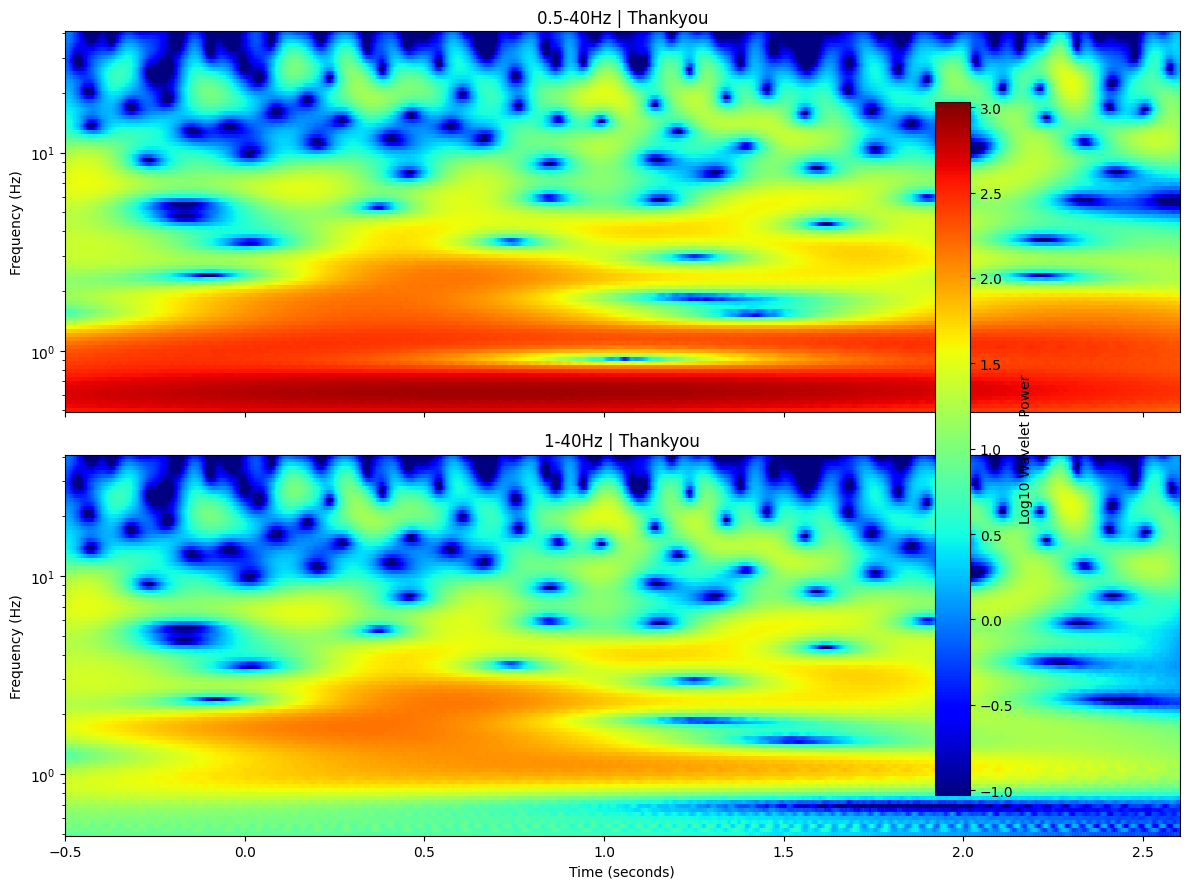

In [15]:
TRIAL_NUMBER = 1
trial_index = TRIAL_NUMBER - 1

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 9),
    sharex=True
)

for ax, filter_name in zip(
    axes,
    ["0.5-40Hz", "1-40Hz"]
):

    power = cwt_results[filter_name][trial_index]

    log_power = np.log10(power + 1e-12)

    mesh = ax.pcolormesh(
        time_seconds,
        cwt_frequencies,
        log_power,
        shading="auto",
        cmap="jet",
        vmin=COLOR_MIN,
        vmax=COLOR_MAX
    )

    ax.set_yscale("log")

    ax.set_ylabel("Frequency (Hz)")

    ax.set_title(
        f"{filter_name} | "
        f"{trial_labels[trial_index]}"
    )

axes[-1].set_xlabel("Time (seconds)")

fig.colorbar(
    mesh,
    ax=axes,
    label="Log10 Wavelet Power"
)

plt.tight_layout()
plt.show()

In [16]:
for root, dirs, files in os.walk(OUTPUT_DIR):

    png_count = sum(
        f.endswith(".png") for f in files
    )

    npz_count = sum(
        f.endswith(".npz") for f in files
    )

    csv_count = sum(
        f.endswith(".csv") for f in files
    )

    if png_count or npz_count or csv_count:

        print(root)

        if png_count:
            print(" PNG files:", png_count)

        if npz_count:
            print(" NPZ files:", npz_count)

        if csv_count:
            print(" CSV files:", csv_count)

/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/experiment_outputs/CWT_Scalograms/0.5-40Hz/Cz/Hello
 PNG files: 10
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/experiment_outputs/CWT_Scalograms/0.5-40Hz/Cz/Helpme
 PNG files: 10
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/experiment_outputs/CWT_Scalograms/0.5-40Hz/Cz/Stop
 PNG files: 10
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/experiment_outputs/CWT_Scalograms/0.5-40Hz/Cz/Thankyou
 PNG files: 10
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/experiment_outputs/CWT_Scalograms/0.5-40Hz/Cz/Yes
 PNG files: 10
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/experiment_outputs/CWT_Scalograms/1-40Hz/Cz/Hello
 PNG files: 10
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/experiment_outputs/CWT_Scalograms/1-40Hz/Cz/Helpme
 PNG files: 10
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/experiment_outputs/CWT_Scalograms/1-40Hz/Cz/Stop
 PNG files: 10
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/e

Total scalogram images found: 100
Contact sheet saved!
/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/experiment_outputs/CWT_Scalograms/ALL_100_CWT_SCALOGRAMS.png
Image dimensions: (3088, 2338)


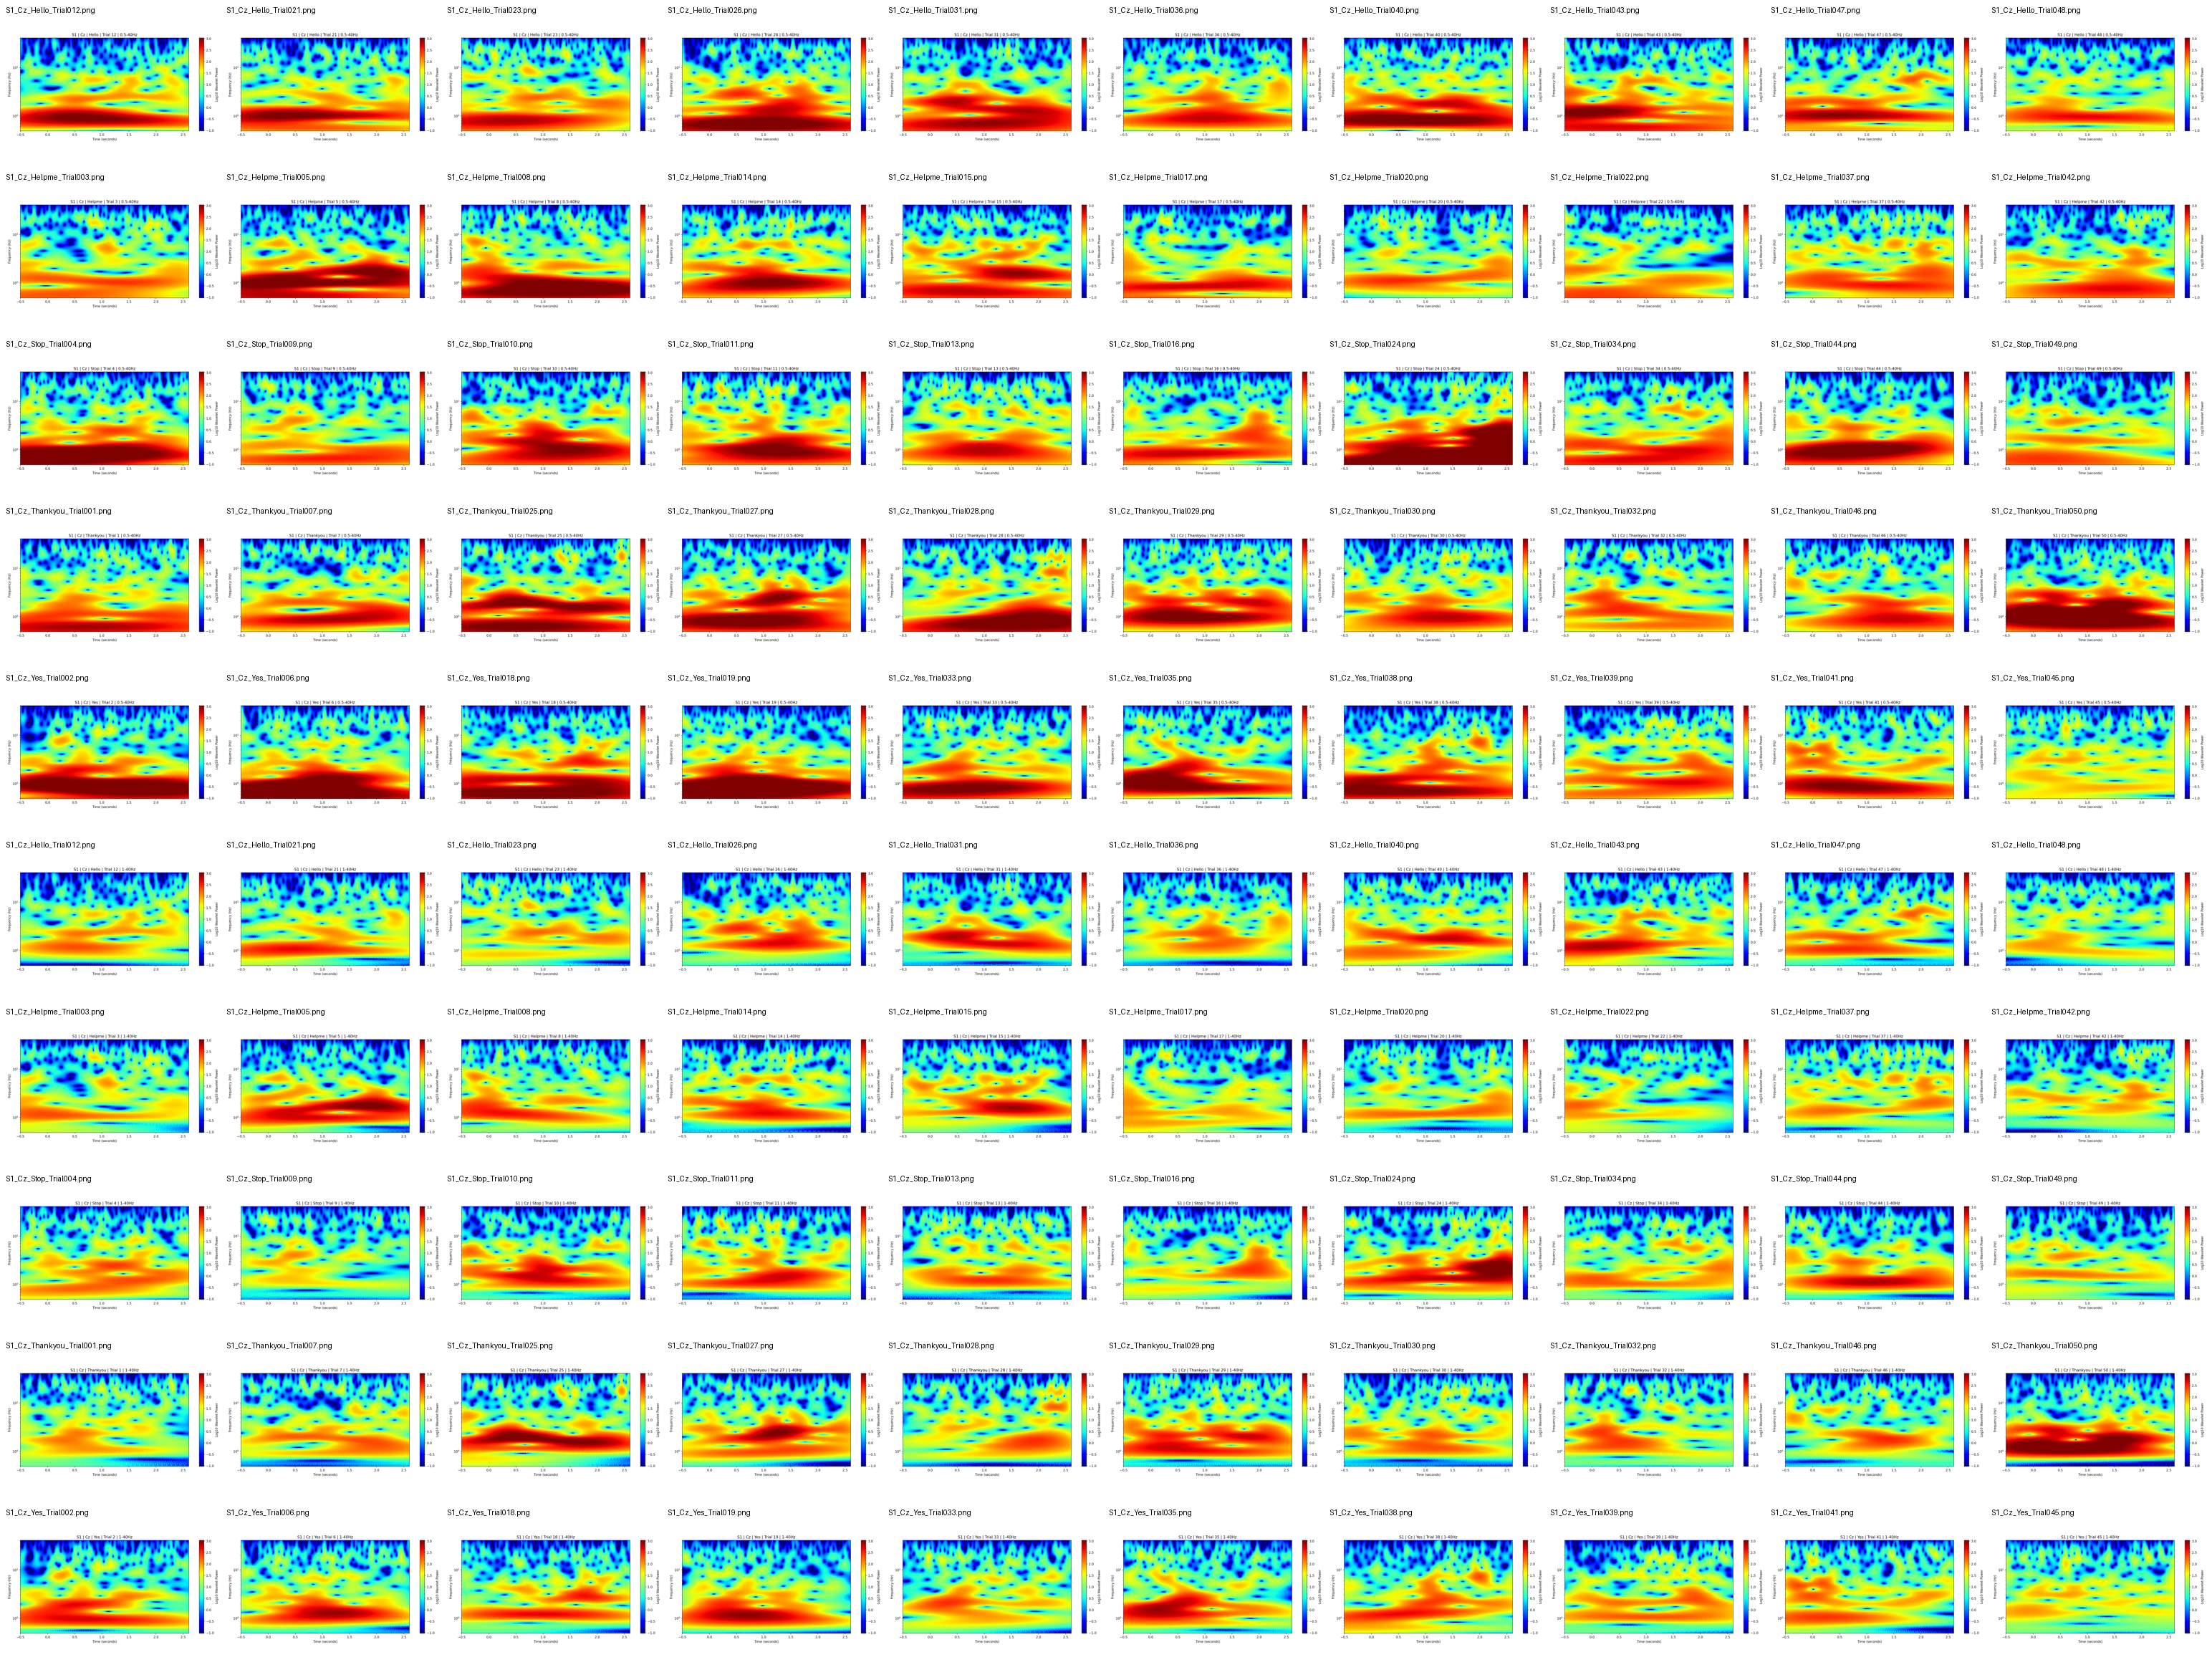

In [17]:
from PIL import Image, ImageDraw, ImageFont
import os
import glob
import math

# Find all 100 scalogram images
image_files = []

for filter_name in ["0.5-40Hz", "1-40Hz"]:
    base_dir = os.path.join(
        OUTPUT_DIR, filter_name, ELECTRODE_NAME
    )

    for class_name in class_names:
        folder = os.path.join(base_dir, class_name)

        files = sorted(glob.glob(os.path.join(folder, "*.png")))
        image_files.extend(files)

print("Total scalogram images found:", len(image_files))

# Contact sheet settings
COLUMNS = 10
THUMB_WIDTH = 300
THUMB_HEIGHT = 190
HEADER_HEIGHT = 35
PADDING = 8

ROWS = math.ceil(len(image_files) / COLUMNS)

sheet_width = COLUMNS * (THUMB_WIDTH + PADDING) + PADDING
sheet_height = ROWS * (THUMB_HEIGHT + HEADER_HEIGHT + PADDING) + PADDING

# Create contact sheet
sheet = Image.new(
    "RGB",
    (sheet_width, sheet_height),
    "white"
)

draw = ImageDraw.Draw(sheet)

try:
    font = ImageFont.truetype("DejaVuSans.ttf", 16)
except:
    font = ImageFont.load_default()

for i, file_path in enumerate(image_files):

    img = Image.open(file_path).convert("RGB")
    img.thumbnail((THUMB_WIDTH, THUMB_HEIGHT))

    row = i // COLUMNS
    col = i % COLUMNS

    x = PADDING + col * (THUMB_WIDTH + PADDING)
    y = PADDING + row * (
        THUMB_HEIGHT + HEADER_HEIGHT + PADDING
    )

    # Add filename above image
    filename = os.path.basename(file_path)

    draw.text(
        (x, y),
        filename,
        fill="black",
        font=font
    )

    sheet.paste(
        img,
        (x, y + HEADER_HEIGHT)
    )

# Save to Google Drive
CONTACT_SHEET_PATH = os.path.join(
    OUTPUT_DIR,
    "ALL_100_CWT_SCALOGRAMS.png"
)

sheet.save(CONTACT_SHEET_PATH)

print("Contact sheet saved!")
print(CONTACT_SHEET_PATH)
print("Image dimensions:", sheet.size)

display(sheet)

In [18]:
import os
import glob
import scipy.io as sio

TRAIN_DIR = "/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/dataset/Training set"

VALIDATION_DIR = "/content/gdrive/MyDrive/Imagined_Speech_EEG_Project/dataset/Validation set"

train_files = sorted(glob.glob(os.path.join(TRAIN_DIR, "*.mat")))
val_files = sorted(glob.glob(os.path.join(VALIDATION_DIR, "*.mat")))

print("TRAINING FILES:", len(train_files))
print("VALIDATION FILES:", len(val_files))

print("\nTRAINING SUBJECTS")
for f in train_files:
    print(os.path.basename(f))

print("\nVALIDATION SUBJECTS")
for f in val_files:
    print(os.path.basename(f))

print("\nINSPECTING FIRST TRAINING FILE")

data = sio.loadmat(train_files[0], squeeze_me=False)

for key, value in data.items():
    if not key.startswith("__"):
        print(key, type(value), getattr(value, "shape", None))

print("\nINSPECTING FIRST VALIDATION FILE")

data = sio.loadmat(val_files[0], squeeze_me=False)

for key, value in data.items():
    if not key.startswith("__"):
        print(key, type(value), getattr(value, "shape", None))

TRAINING FILES: 15
VALIDATION FILES: 15

TRAINING SUBJECTS
Data_Sample01.mat
Data_Sample02.mat
Data_Sample03.mat
Data_Sample04.mat
Data_Sample05.mat
Data_Sample06.mat
Data_Sample07.mat
Data_Sample08.mat
Data_Sample09.mat
Data_Sample10.mat
Data_Sample11.mat
Data_Sample12.mat
Data_Sample13.mat
Data_Sample14.mat
Data_Sample15.mat

VALIDATION SUBJECTS
Data_Sample01.mat
Data_Sample02.mat
Data_Sample03.mat
Data_Sample04.mat
Data_Sample05.mat
Data_Sample06.mat
Data_Sample07.mat
Data_Sample08.mat
Data_Sample09.mat
Data_Sample10.mat
Data_Sample11.mat
Data_Sample12.mat
Data_Sample13.mat
Data_Sample14.mat
Data_Sample15.mat

INSPECTING FIRST TRAINING FILE
epo_train <class 'numpy.ndarray'> (1, 1)
mnt <class 'numpy.ndarray'> (1, 1)

INSPECTING FIRST VALIDATION FILE
epo_validation <class 'numpy.ndarray'> (1, 1)
mnt <class 'numpy.ndarray'> (1, 1)
